In [1]:
%pip install -U ultralytics roboflow scikit-learn seaborn pandas matplotlib pillow pyyaml tqdm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.4 MB 670.4 kB/s eta 0:00:02
   -------------- ------------------------- 0.5/1.4 MB 670.4 kB/s eta 0:00:02
   --------------------- ------------------ 0.8/1.4 MB 657.8 kB/s eta 0:00:01
   --------------------- ------------------ 0.8/1.4 MB 657.8 kB/s eta 0:00:01
   ----------------------------- ---------- 1.0/1.4 MB 662.0 kB/s eta 0:00:01
   ----------------------------- ---------- 1.0/1.4 MB 662.0 kB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 720.8 kB/s  0:00:01
   ---------------------------------------- 0.0/7.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/7.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/7.4 MB ? eta -:--:--
   - --------------------------------------

In [18]:
from pathlib import Path
import os
import random
import shutil
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import torch
import torch.nn as nn

from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    accuracy_score
)

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


Setting Up project Folders

In [3]:
PROJECT_DIR = Path(r"G:\Code\smart-waste-detection")

DATA_DIR = PROJECT_DIR / "data"
CROP_DIR = PROJECT_DIR / "cnn_crops"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

for folder in [DATA_DIR, CROP_DIR, RESULTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: G:\Code\smart-waste-detection


Automatic Dataset Download

In [6]:
from getpass import getpass
from roboflow import Roboflow

api_key = getpass("Enter your Roboflow API key: ")

rf = Roboflow(api_key=api_key)

workspace = rf.workspace("object-detection-cfmul")
project = workspace.project("waste-detection-0momv")

# Download dataset version 1 in YOLO11-compatible format
dataset = project.version(1).download(
    "yolov11",
    location=str(DATA_DIR / "waste_dataset")
)

DATASET_PATH = Path(dataset.location)

print("Dataset downloaded to:", DATASET_PATH)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to G:\Code\smart-waste-detection\data\waste_dataset in yolov11:: 100%|██████████| 9551/9551 [00:03<00:00, 3035.08it/s]


Dataset downloaded to: G:\Code\smart-waste-detection\data\waste_dataset


Read the dataset configuration

In [7]:
DATA_YAML = DATASET_PATH / "data.yaml"

with open(DATA_YAML, "r", encoding="utf-8") as file:
    data_config = yaml.safe_load(file)

class_names = data_config["names"]

if isinstance(class_names, dict):
    class_names = [
        class_names[k] for k in sorted(class_names, key=lambda x: int(x))
    ]

num_classes = len(class_names)

print("Dataset:", DATASET_PATH)
print("Number of classes:", num_classes)
print("Classes:", class_names)
print("Configuration:")
print(data_config)

Dataset: G:\Code\smart-waste-detection\data\waste_dataset
Number of classes: 6
Classes: ['Garbage_Bag', 'Glass', 'Paper_Bag', 'Pet_Bottle', 'Plastic_Bag', 'can']
Configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 6, 'names': ['Garbage_Bag', 'Glass', 'Paper_Bag', 'Pet_Bottle', 'Plastic_Bag', 'can'], 'roboflow': {'workspace': 'object-detection-cfmul', 'project': 'waste-detection-0momv', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/object-detection-cfmul/waste-detection-0momv/dataset/1'}}


In [19]:
from pathlib import Path

PROJECT_DIR = Path(r"G:\Code\smart-waste-detection")
DATASET_PATH = PROJECT_DIR / "dataset"

print("Dataset path:", DATASET_PATH)
print("Path exists:", DATASET_PATH.exists())

Dataset path: G:\Code\smart-waste-detection\dataset
Path exists: False


In [20]:
for folder in PROJECT_DIR.iterdir():
    if folder.is_dir():
        print(folder.name)

cnn_crops
data
models
results


Inspect the dataset splits

In [21]:
for split in ["train", "valid", "test"]:
    image_dir = DATASET_PATH / split / "images"
    label_dir = DATASET_PATH / split / "labels"

    if image_dir.exists():
        images = [
            p for p in image_dir.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        ]
        labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

        print(
            f"{split:6s} | Images: {len(images):5d} | "
            f"Label files: {len(labels):5d}"
        )
    else:
        print(f"{split}: folder not found")

train: folder not found
valid: folder not found
test: folder not found


Visualize annotated images

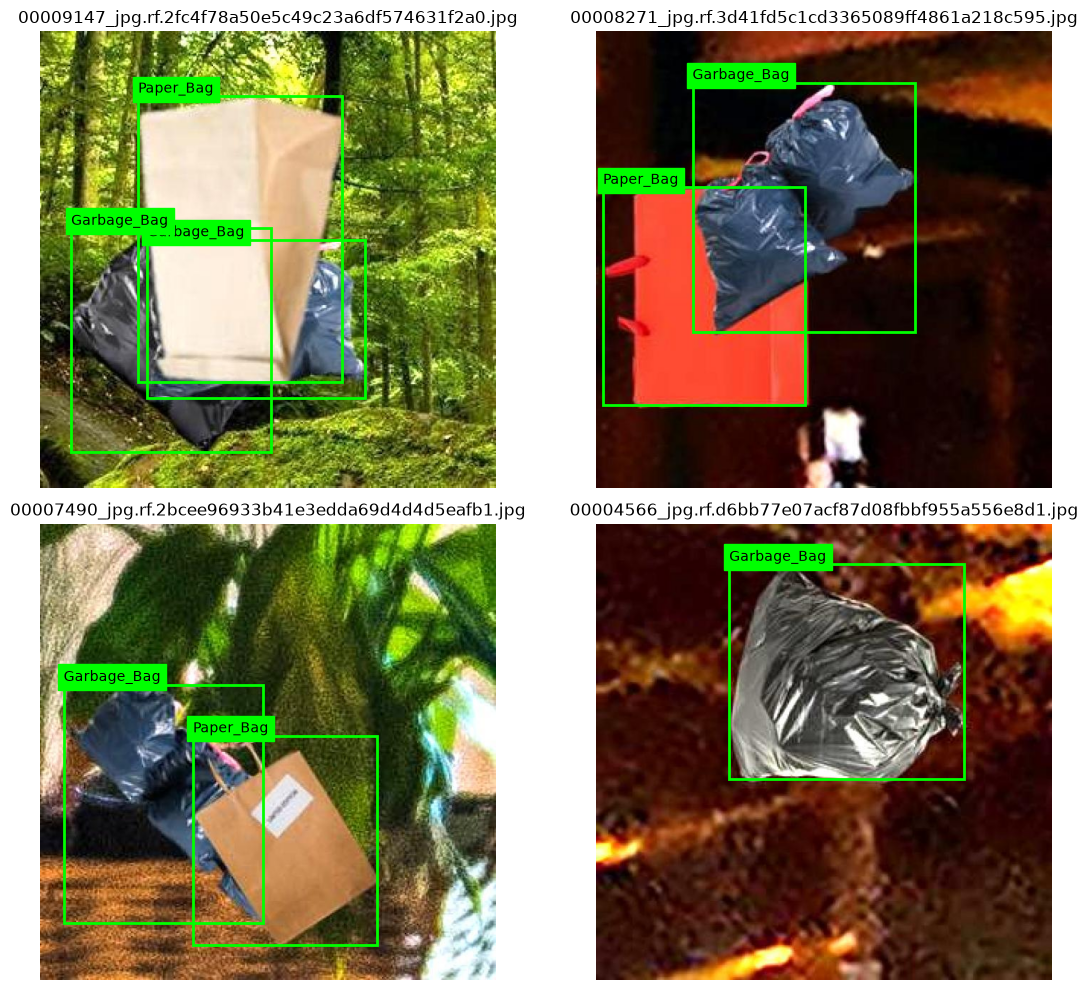

In [17]:
import matplotlib.patches as patches

train_images_dir = DATASET_PATH / "train" / "images"
train_labels_dir = DATASET_PATH / "train" / "labels"

image_paths = [
    p for p in train_images_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

sample_paths = random.sample(image_paths, min(4, len(image_paths)))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, sample_paths):
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    ax.imshow(image)
    ax.set_title(image_path.name)
    ax.axis("off")

    label_path = train_labels_dir / f"{image_path.stem}.txt"

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()
            if len(values) < 5:
                continue

            cls_id, x, y, w, h = map(float, values[:5])

            x1 = (x - w / 2) * width
            y1 = (y - h / 2) * height

            rect = patches.Rectangle(
                (x1, y1),
                w * width,
                h * height,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )
            ax.add_patch(rect)

            ax.text(
                x1, max(0, y1 - 5),
                class_names[int(cls_id)],
                color="black",
                backgroundcolor="lime"
            )

plt.tight_layout()
plt.show()

Prepare object crops for the CNN classifier

In [10]:
import cv2

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Start with a clean crop dataset
if CROP_DIR.exists():
    shutil.rmtree(CROP_DIR)
CROP_DIR.mkdir(parents=True)

crop_counts = {}

for split in ["train", "valid", "test"]:
    image_dir = DATASET_PATH / split / "images"
    label_dir = DATASET_PATH / split / "labels"

    if not image_dir.exists():
        continue

    for class_name in class_names:
        (CROP_DIR / split / class_name).mkdir(parents=True, exist_ok=True)

    image_paths = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in tqdm(image_paths, desc=f"Cropping {split}"):
        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            continue

        image = cv2.imread(str(image_path))
        if image is None:
            continue

        height, width = image.shape[:2]

        for index, line in enumerate(label_path.read_text().splitlines()):
            values = line.split()
            if len(values) < 5:
                continue

            cls_id, x, y, w, h = map(float, values[:5])
            cls_id = int(cls_id)

            if cls_id < 0 or cls_id >= num_classes:
                continue

            x1 = max(0, int((x - w / 2) * width))
            y1 = max(0, int((y - h / 2) * height))
            x2 = min(width, int((x + w / 2) * width))
            y2 = min(height, int((y + h / 2) * height))

            if x2 <= x1 or y2 <= y1:
                continue

            crop = image[y1:y2, x1:x2]

            if crop.size == 0:
                continue

            output_dir = CROP_DIR / split / class_names[cls_id]
            output_path = output_dir / f"{image_path.stem}_{index}.jpg"

            cv2.imwrite(str(output_path), crop)
            crop_counts[(split, class_names[cls_id])] = (
                crop_counts.get((split, class_names[cls_id]), 0) + 1
            )

print("Object crops created.")
print(pd.Series(crop_counts).unstack(fill_value=0))

Cropping train:   0%|          | 0/3337 [00:00<?, ?it/s]

Cropping valid:   0%|          | 0/959 [00:00<?, ?it/s]

Cropping test:   0%|          | 0/477 [00:00<?, ?it/s]

Object crops created.
       Garbage_Bag  Glass  Paper_Bag  Pet_Bottle  Plastic_Bag  can
test           115    115        115         115          115  115
train          806    806        806         806          806  806
valid          230    230        230         230          230  230


Check crop distribution

split,test,train,valid
class,,,
Garbage_Bag,115,806,230
Glass,115,806,230
Paper_Bag,115,806,230
Pet_Bottle,115,806,230
Plastic_Bag,115,806,230
can,115,806,230


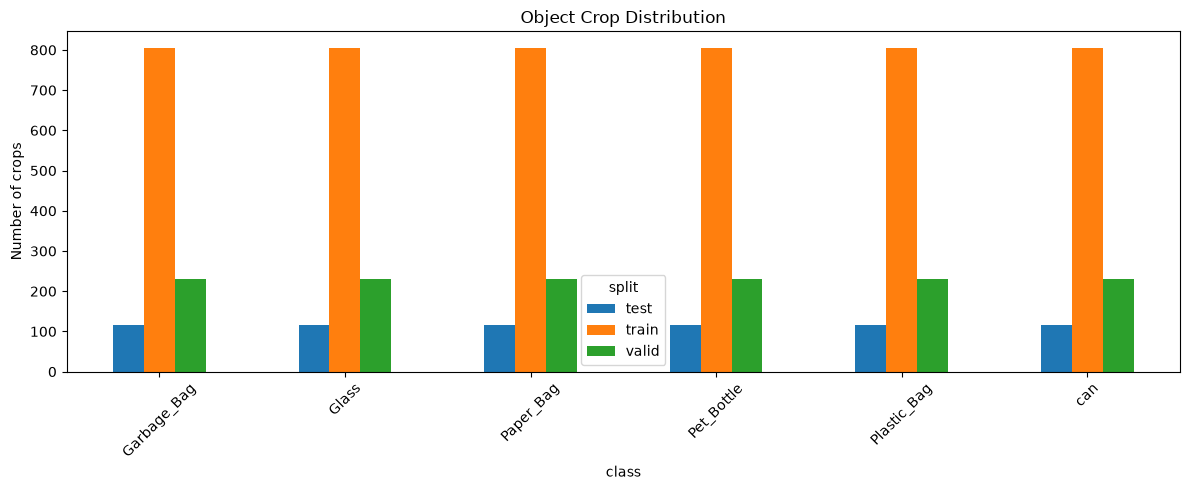

In [11]:
crop_rows = []

for split in ["train", "valid", "test"]:
    for class_name in class_names:
        folder = CROP_DIR / split / class_name
        count = len(list(folder.glob("*.jpg"))) if folder.exists() else 0

        crop_rows.append({
            "split": split,
            "class": class_name,
            "count": count
        })

crop_df = pd.DataFrame(crop_rows)
display(crop_df.pivot(index="class", columns="split", values="count"))

crop_df.pivot(
    index="class", columns="split", values="count"
).plot(kind="bar", figsize=(12, 5))

plt.title("Object Crop Distribution")
plt.ylabel("Number of crops")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Build a CNN classifier from scratch

In [24]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    CROP_DIR / "train", transform=train_transform
)
val_dataset = datasets.ImageFolder(
    CROP_DIR / "valid", transform=eval_transform
)
test_dataset = datasets.ImageFolder(
    CROP_DIR / "test", transform=eval_transform
)

cnn_class_names = train_dataset.classes
cnn_num_classes = len(cnn_class_names)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("CNN classes:", cnn_class_names)
print("Train crops:", len(train_dataset))
print("Validation crops:", len(val_dataset))
print("Test crops:", len(test_dataset))

CNN classes: ['Garbage_Bag', 'Glass', 'Paper_Bag', 'Pet_Bottle', 'Plastic_Bag', 'can']
Train crops: 4836
Validation crops: 1380
Test crops: 690


Build a CNN with dropout

In [26]:
class WasteCNN(nn.Module):
    def __init__(self, num_classes, dropout=0.27):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


cnn_model = WasteCNN(
    num_classes=cnn_num_classes,
    dropout=0.27
).to(device)

print(cnn_model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
)

WasteCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, aff

Train with early stopping

In [27]:
def train_cnn(
    model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=0.001,
    weight_decay=1e-3,
    patience=8,
    save_path=MODELS_DIR / "cnn_best.pt"
):
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in tqdm(
            train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False
        ):
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * images.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()
            train_total += labels.size(0)

        train_loss = train_loss_sum / train_total
        train_accuracy = train_correct / train_total

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * images.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_accuracy = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Epoch {epoch+1:02d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Train acc: {train_accuracy:.3f} | "
            f"Val acc: {val_accuracy:.3f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, save_path)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_weights)
    return model, pd.DataFrame(history)


cnn_model, cnn_history = train_cnn(
    cnn_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    patience=5
)

Epoch 1/50:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 01 | Train loss: 1.2226 | Val loss: 1.1138 | Train acc: 0.555 | Val acc: 0.600


Epoch 2/50:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 02 | Train loss: 1.0453 | Val loss: 1.1303 | Train acc: 0.620 | Val acc: 0.602


Epoch 3/50:   0%|          | 0/152 [00:00<?, ?it/s]

...

Epoch 11 | Train loss: 0.7537 | Val loss: 0.8336 | Train acc: 0.735 | Val acc: 0.688


Epoch 12/50:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 12 | Train loss: 0.7550 | Val loss: 0.8380 | Train acc: 0.728 | Val acc: 0.699


Epoch 13/50:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 13 | Train loss: 0.7433 | Val loss: 0.8472 | Train acc: 0.731 | Val acc: 0.704
Early stopping triggered.


Plot CNN training and validation curves

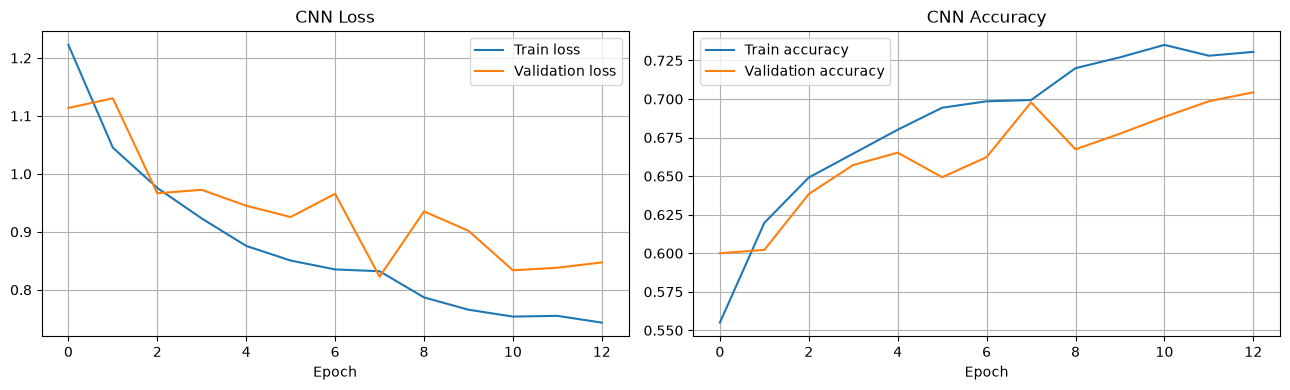

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(cnn_history["train_loss"], label="Train loss")
axes[0].plot(cnn_history["val_loss"], label="Validation loss")
axes[0].set_title("CNN Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(cnn_history["train_accuracy"], label="Train accuracy")
axes[1].plot(cnn_history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("CNN Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "cnn_training_curves.png", dpi=150)
plt.show()

Evaluate the CNN on the test set

In [29]:
cnn_model.eval()

all_true = []
all_pred = []

start_time = time.perf_counter()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_pred.extend(predictions)
        all_true.extend(labels.numpy())

elapsed = time.perf_counter() - start_time

print("Test accuracy:", accuracy_score(all_true, all_pred))
print(
    classification_report(
        all_true,
        all_pred,
        labels=list(range(len(cnn_class_names))),
        target_names=cnn_class_names,
        zero_division=0
    )
)
print("Evaluation time (seconds):", round(elapsed, 2))

Test accuracy: 0.7246376811594203
              precision    recall  f1-score   support

 Garbage_Bag       0.85      0.81      0.83       115
       Glass       0.61      0.76      0.68       115
   Paper_Bag       0.72      0.72      0.72       115
  Pet_Bottle       0.73      0.81      0.77       115
 Plastic_Bag       0.70      0.68      0.69       115
         can       0.79      0.57      0.66       115

    accuracy                           0.72       690
   macro avg       0.73      0.72      0.72       690
weighted avg       0.73      0.72      0.72       690

Evaluation time (seconds): 8.14


CNN confusion matrix

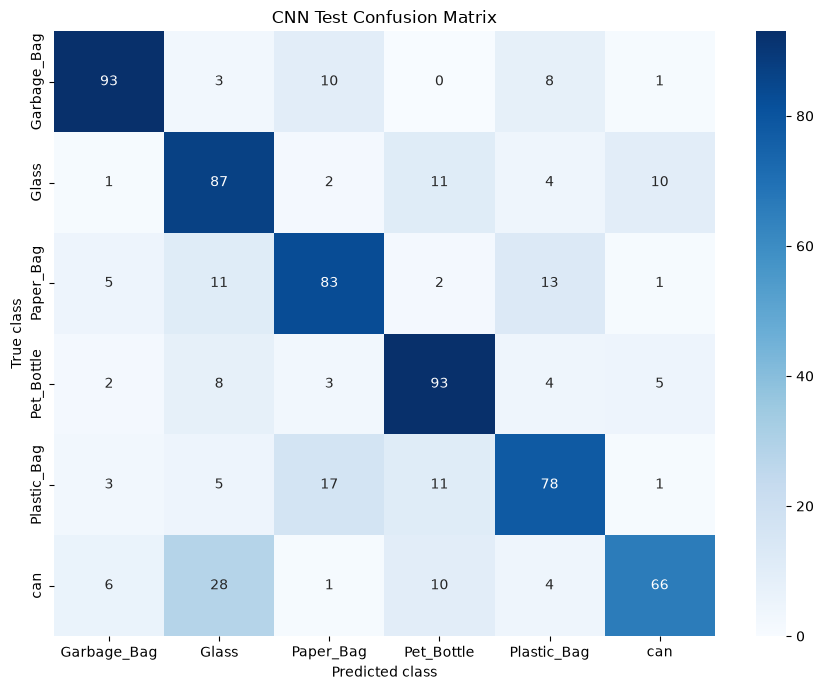

In [30]:
cm = confusion_matrix(
    all_true,
    all_pred,
    labels=list(range(len(cnn_class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cnn_class_names,
    yticklabels=cnn_class_names
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("CNN Test Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "cnn_confusion_matrix.png", dpi=150)
plt.show()

Hyperparameter tuning for the CNN

In [31]:
cnn_tuning_configs = [
    {"lr": 1e-3, "dropout": 0.2, "weight_decay": 1e-4},
    {"lr": 1e-3, "dropout": 0.5, "weight_decay": 1e-4},
    {"lr": 3e-4, "dropout": 0.4, "weight_decay": 1e-4},
]

cnn_tuning_results = []

for i, config in enumerate(cnn_tuning_configs, start=1):
    print(f"\nConfiguration {i}: {config}")

    model = WasteCNN(
        num_classes=cnn_num_classes,
        dropout=config["dropout"]
    ).to(device)

    model, history = train_cnn(
        model,
        train_loader,
        val_loader,
        epochs=50,
        learning_rate=config["lr"],
        weight_decay=config["weight_decay"],
        patience=8,
        save_path=MODELS_DIR / f"cnn_tuning_{i}.pt"
    )

    best_epoch = history["val_loss"].idxmin()

    cnn_tuning_results.append({
        **config,
        "best_val_loss": history.loc[best_epoch, "val_loss"],
        "best_val_accuracy": history.loc[best_epoch, "val_accuracy"],
        "best_epoch": int(best_epoch + 1)
    })

cnn_tuning_df = pd.DataFrame(cnn_tuning_results)
display(cnn_tuning_df.sort_values("best_val_loss"))

cnn_tuning_df.to_csv(
    RESULTS_DIR / "cnn_hyperparameter_tuning.csv",
    index=False
)


Configuration 1: {'lr': 0.001, 'dropout': 0.2, 'weight_decay': 0.0001}


Epoch 1/50:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 01 | Train loss: 1.1833 | Val loss: 1.1573 | Train acc: 0.559 | Val acc: 0.601


Epoch 2/50:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 02 | Train loss: 1.0005 | Val loss: 1.1123 | Train acc: 0.634 | Val acc: 0.610


...

Epoch 31/50:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 31 | Train loss: 0.6198 | Val loss: 0.6368 | Train acc: 0.782 | Val acc: 0.786


Epoch 32/50:   0%|          | 0/152 [00:00<?, ?it/s]

Epoch 32 | Train loss: 0.6175 | Val loss: 0.6432 | Train acc: 0.779 | Val acc: 0.786
Early stopping triggered.


,lr,dropout,weight_decay,best_val_loss,best_val_accuracy,best_epoch
0,0.0010,0.2,0.0001,0.490878,0.840580,50
2,0.0003,0.4,0.0001,0.620859,0.787681,24
1,0.0010,0.5,0.0001,0.732896,0.734058,14


Baseline YOLO training

In [32]:
YOLO_MODEL = "yolo11m.pt"
YOLO_EPOCHS = 40
YOLO_IMAGE_SIZE = 640
YOLO_BATCH_SIZE = 16

yolo_model = YOLO(YOLO_MODEL)

yolo_train_results = yolo_model.train(
    data=str(DATA_YAML),
    epochs=YOLO_EPOCHS,
    imgsz=YOLO_IMAGE_SIZE,
    batch=YOLO_BATCH_SIZE,
    patience=8,             # Early stopping
    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0001,
    workers=0,              # Safe starting point on Windows
    seed=SEED,
    deterministic=True,
    plots=True,
    project=str(RESULTS_DIR / "yolo_runs"),
    name="baseline",
    exist_ok=True
)

print("YOLO training complete.")
print("Best model:", yolo_train_results.save_dir / "weights" / "best.pt")

Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\Code\smart-waste-detection\data\waste_dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline

Plot YOLO training curves

In [33]:
yolo_run_dir = Path(yolo_train_results.save_dir)
yolo_csv_path = yolo_run_dir / "results.csv"

yolo_history = pd.read_csv(yolo_csv_path)
yolo_history.columns = yolo_history.columns.str.strip()

print(yolo_history.columns.tolist())

display(yolo_history.tail())

['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
35,36,10432.0,0.55200,0.43834,1.08357,0.94337,0.86044,0.94182,0.79939,0.60964,0.46355,1.07969,0.000134,0.000134,0.000134
36,37,10671.4,0.54240,0.43466,1.08038,0.94560,0.86327,0.93811,0.79909,0.59185,0.46936,1.07056,0.000109,0.000109,0.000109
37,38,10983.0,0.53303,0.40823,1.06224,0.91967,0.89531,0.94298,0.80568,0.58557,0.44601,1.06883,0.000084,0.000084,0.000084
38,39,11256.6,0.51839,0.39722,1.04869,0.93578,0.88434,0.94728,0.81492,0.56950,0.43843,1.05795,0.000060,0.000060,0.000060
39,40,11441.9,0.50515,0.37947,1.04522,0.94107,0.88094,0.94883,0.81545,0.57013,0.43059,1.05496,0.000035,0.000035,0.000035


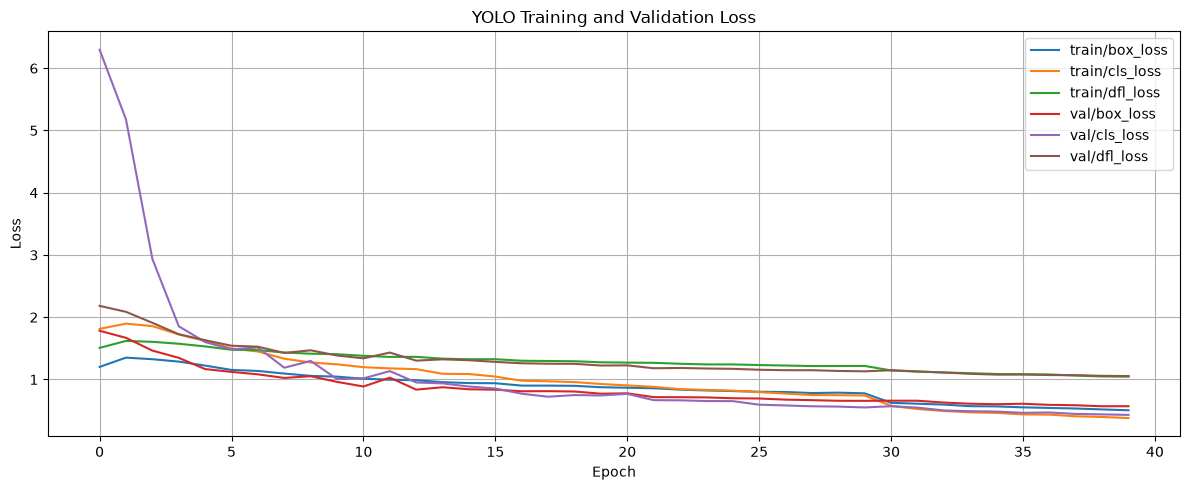

In [34]:
loss_columns = [
    col for col in yolo_history.columns
    if "loss" in col.lower()
    and ("train" in col.lower() or "val" in col.lower())
]

if loss_columns:
    yolo_history[loss_columns].plot(figsize=(12, 5))
    plt.title("YOLO Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "yolo_loss_curves.png", dpi=150)
    plt.show()
else:
    print("Loss columns not detected. Inspect the column names printed above.")

Separate Yolo parameter tuning

In [36]:
yolo_tuning_configs = [
    {"lr0": 0.001, "weight_decay": 0.0005},
    {"lr0": 0.0003, "weight_decay": 0.0005},
    {"lr0": 0.001, "weight_decay": 0.001},
]

yolo_tuning_results = []

for i, config in enumerate(yolo_tuning_configs, start=1):
    print(f"\nYOLO configuration {i}: {config}")

    model = YOLO("yolo11n.pt")

    result = model.train(
        data=str(DATA_YAML),
        epochs=25,
        imgsz=YOLO_IMAGE_SIZE,
        batch=YOLO_BATCH_SIZE,
        patience=5,
        optimizer="AdamW",
        workers=0,
        seed=SEED,
        deterministic=True,
        plots=True,
        project=str(RESULTS_DIR / "yolo_runs"),
        name=f"tuning_{i}",
        exist_ok=True,
        **config
    )

    run_dir = Path(result.save_dir)
    csv_path = run_dir / "results.csv"

    history = pd.read_csv(csv_path)
    history.columns = history.columns.str.strip()

    # Use validation mAP50-95 to choose the best epoch
    map_col = next(
        (
            col for col in history.columns
            if "metrics/mAP50-95(B)" in col
            or "metrics/mAP50-95" in col
        ),
        None
    )

    if map_col is not None:
        best_row = history.loc[history[map_col].idxmax()]
        best_map = float(best_row[map_col])
        best_epoch = int(best_row.get("epoch", history[map_col].idxmax()))
    else:
        best_map = np.nan
        best_epoch = np.nan

    yolo_tuning_results.append({
        **config,
        "best_val_map50_95": best_map,
        "best_epoch": best_epoch,
        "run_dir": str(run_dir)
    })

yolo_tuning_df = pd.DataFrame(yolo_tuning_results)
display(yolo_tuning_df.sort_values("best_val_map50_95", ascending=False))

yolo_tuning_df.to_csv(
    RESULTS_DIR / "yolo_hyperparameter_tuning.csv",
    index=False
)


YOLO configuration 1: {'lr0': 0.001, 'weight_decay': 0.0005}
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\Code\smart-waste-detection\data\waste_dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.

,lr0,weight_decay,best_val_map50_95,best_epoch,run_dir
1,0.0003,0.0005,0.83067,25,G:\Code\smart-waste-detection\results\yolo_run...
0,0.0010,0.0005,0.81135,25,G:\Code\smart-waste-detection\results\yolo_run...
2,0.0010,0.0010,0.80683,25,G:\Code\smart-waste-detection\results\yolo_run...


Final Eval

In [37]:
valid_tuning = yolo_tuning_df.dropna(subset=["best_val_map50_95"])

if not valid_tuning.empty:
    best_tuning_row = valid_tuning.loc[
        valid_tuning["best_val_map50_95"].idxmax()
    ]
    best_run_dir = Path(best_tuning_row["run_dir"])
    best_yolo_path = best_run_dir / "weights" / "best.pt"
else:
    best_yolo_path = yolo_run_dir / "weights" / "best.pt"

print("Selected YOLO checkpoint:", best_yolo_path)

best_yolo = YOLO(str(best_yolo_path))

test_metrics = best_yolo.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=YOLO_IMAGE_SIZE,
    batch=YOLO_BATCH_SIZE,
    workers=0,
    plots=True,
    project=str(RESULTS_DIR / "yolo_evaluation"),
    name="test",
    exist_ok=True
)

yolo_test_results = {
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50),
    "mAP50_95": float(test_metrics.box.map)
}

print(pd.Series(yolo_test_results))

Selected YOLO checkpoint: G:\Code\smart-waste-detection\results\yolo_runs\tuning_2\weights\best.pt
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 4.9±2.1 MB/s, size: 37.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning G:\Code\smart-waste-detection\data\waste_dataset\test\labels... 477 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 477/477 577.9it/s 0.8s0.0s
val: New cache created: G:\Code\smart-waste-detection\data\waste_dataset\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 5.9it/s 5.1s0.2s
                   all        477        690      0.948      0.913      0.964      0.825
        

View the YOLO confusion matrix

Evaluation output directory: G:\Code\smart-waste-detection\results\yolo_evaluation\test


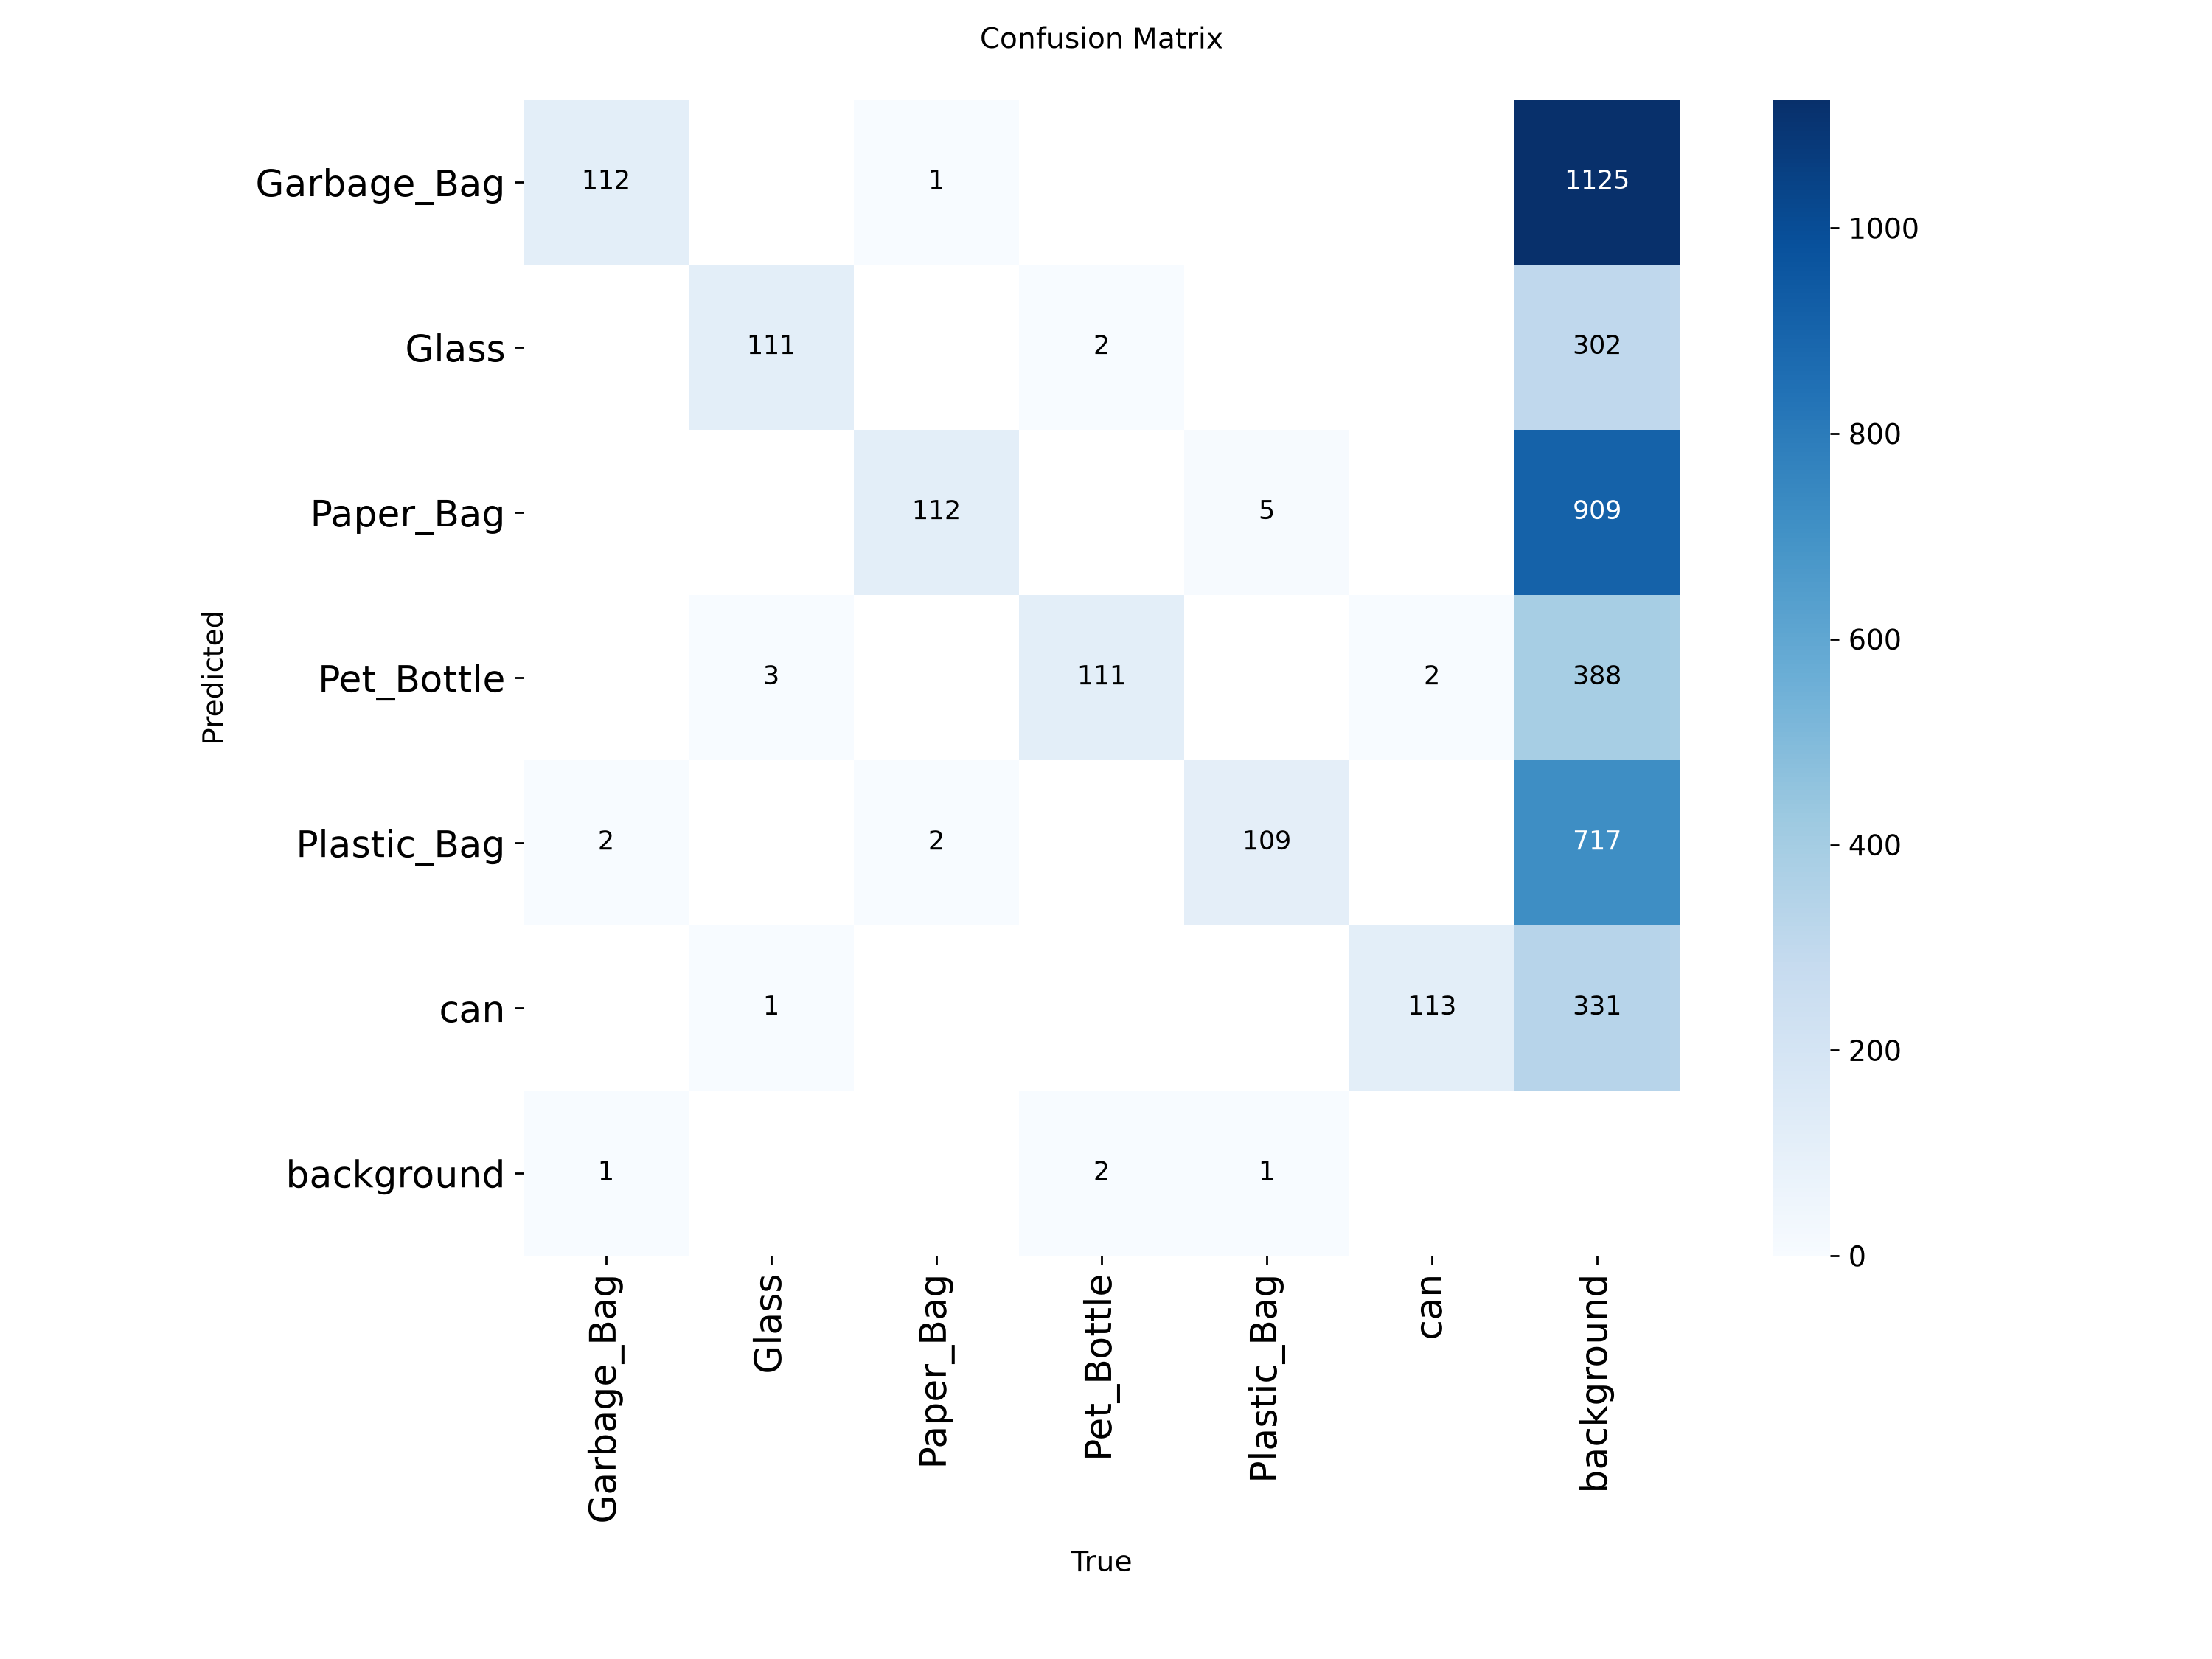

In [38]:
evaluation_dir = Path(test_metrics.save_dir)
print("Evaluation output directory:", evaluation_dir)

confusion_path = evaluation_dir / "confusion_matrix.png"

if confusion_path.exists():
    display(Image.open(confusion_path))
else:
    print("Confusion matrix not found at:", confusion_path)
    print("Check the evaluation output directory for generated plots.")

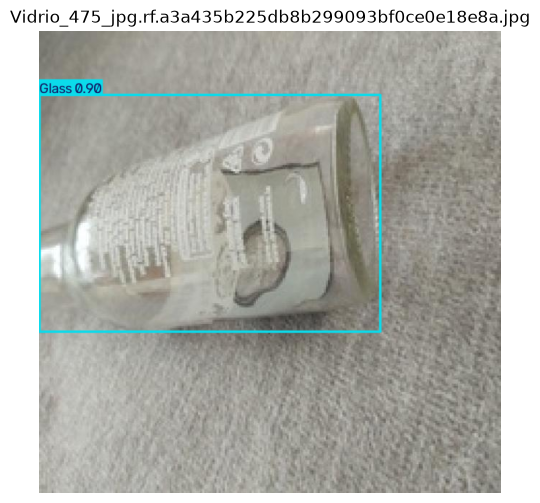

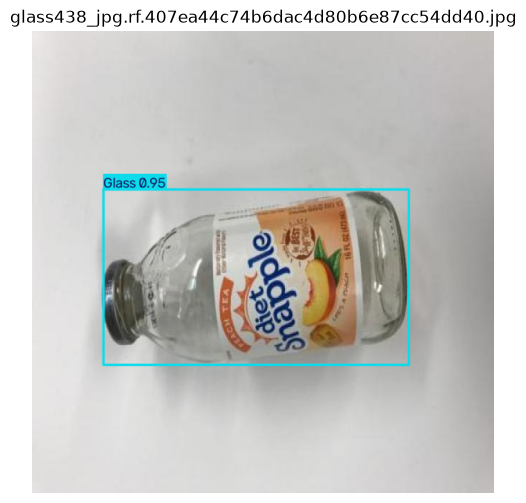

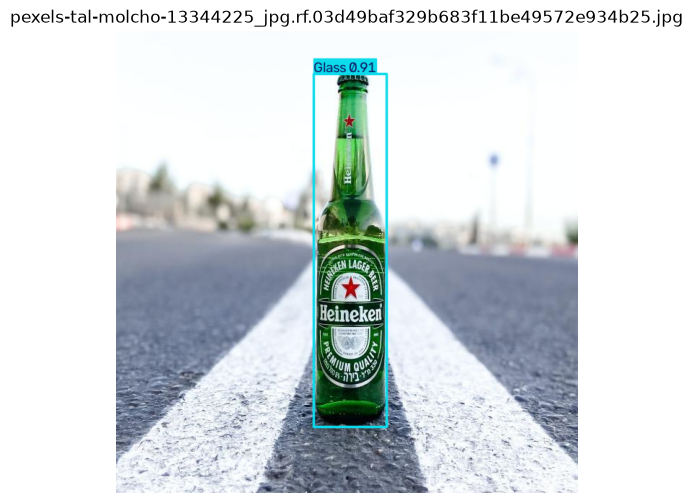

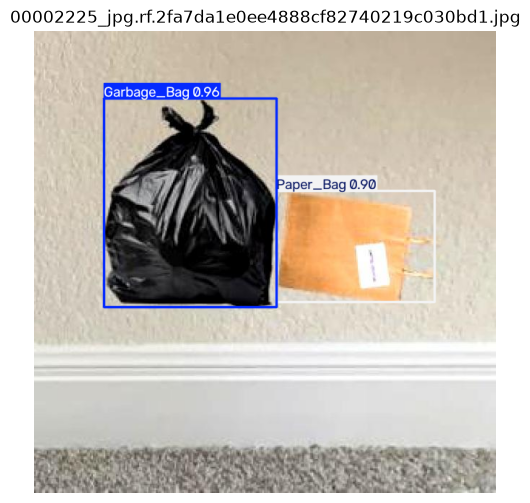

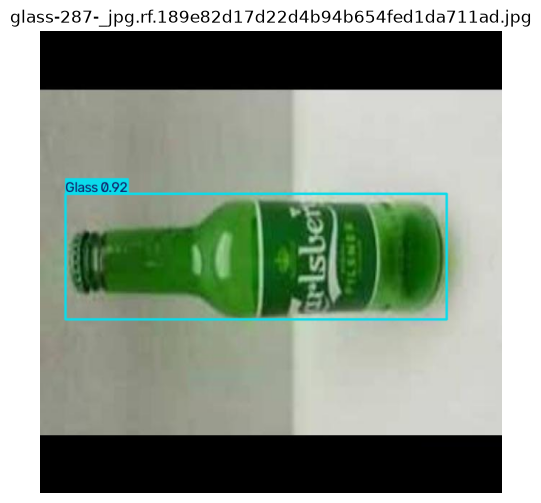

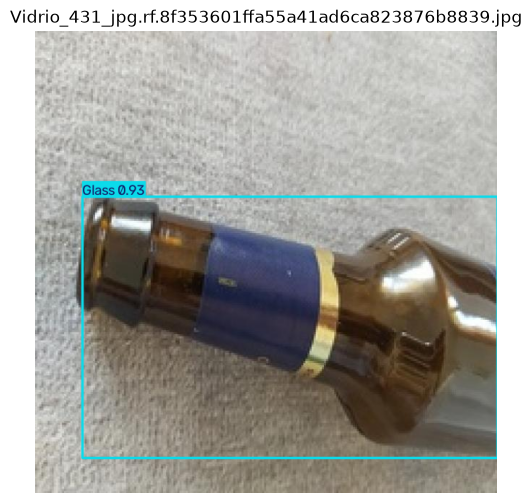

In [39]:
test_images_dir = DATASET_PATH / "test" / "images"

test_image_paths = [
    p for p in test_images_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

sample_images = random.sample(
    test_image_paths,
    min(6, len(test_image_paths))
)

inference_dir = RESULTS_DIR / "predictions"
inference_dir.mkdir(parents=True, exist_ok=True)

for image_path in sample_images:
    predictions = best_yolo.predict(
        source=str(image_path),
        imgsz=YOLO_IMAGE_SIZE,
        conf=0.25,
        save=False,
        verbose=False
    )

    plotted = predictions[0].plot()

    output_path = inference_dir / f"{image_path.stem}_prediction.jpg"
    cv2.imwrite(str(output_path), plotted)

    plt.figure(figsize=(9, 6))
    plt.imshow(cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB))
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

Select and evaluate the best tuned CNN

In [40]:
best_cnn_row = cnn_tuning_df.loc[
    cnn_tuning_df["best_val_loss"].idxmin()
]

best_cnn = WasteCNN(
    num_classes=cnn_num_classes,
    dropout=float(best_cnn_row["dropout"])
).to(device)

# Load the best checkpoint for the selected configuration
best_cnn_checkpoint = MODELS_DIR / (
    f"cnn_tuning_{cnn_tuning_df.index.get_loc(best_cnn_row.name) + 1}.pt"
)

best_cnn.load_state_dict(
    torch.load(best_cnn_checkpoint, map_location=device, weights_only=True)
)

best_cnn.eval()

all_true = []
all_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = best_cnn(images)

        all_pred.extend(outputs.argmax(dim=1).cpu().tolist())
        all_true.extend(labels.tolist())

print("Best CNN configuration:")
print(best_cnn_row)

print("\nFinal CNN test accuracy:", accuracy_score(all_true, all_pred))
print(
    classification_report(
        all_true,
        all_pred,
        labels=list(range(len(cnn_class_names))),
        target_names=cnn_class_names,
        zero_division=0
    )
)

Best CNN configuration:
lr                    0.001000
dropout               0.200000
weight_decay          0.000100
best_val_loss         0.490878
best_val_accuracy     0.840580
best_epoch           50.000000
Name: 0, dtype: float64

Final CNN test accuracy: 0.8188405797101449
              precision    recall  f1-score   support

 Garbage_Bag       0.87      0.85      0.86       115
       Glass       0.88      0.78      0.83       115
   Paper_Bag       0.74      0.90      0.82       115
  Pet_Bottle       0.79      0.87      0.83       115
 Plastic_Bag       0.84      0.67      0.74       115
         can       0.83      0.83      0.83       115

    accuracy                           0.82       690
   macro avg       0.82      0.82      0.82       690
weighted avg       0.82      0.82      0.82       690



In [43]:
from torchvision import transforms

# Use the same image size as your CNN training
img_size = globals().get("IMG_SIZE", 128)

test_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Test transform created. Image size:", img_size)


Test transform created. Image size: 224


Device: cuda

CNN checkpoint candidates:
1. G:\Code\smart-waste-detection\models\cnn_best.pt
2. G:\Code\smart-waste-detection\models\cnn_tuning_3.pt
3. G:\Code\smart-waste-detection\models\cnn_tuning_2.pt
4. G:\Code\smart-waste-detection\models\cnn_tuning_1.pt

Selected checkpoint: G:\Code\smart-waste-detection\models\cnn_best.pt

CNN test results:
Precision: 0.7324
Recall:    0.7246
F1-score:  0.7241

YOLO results read from: G:\Code\smart-waste-detection\results\yolo_runs\tuning_2\results.csv


,Metric,CNN,YOLO
0,Precision,0.7324,0.9461
1,Recall,0.7246,0.9140
2,F1-score,0.7241,0.9298
3,mAP@50,NaN,0.9576
4,mAP@50-95,NaN,0.8307


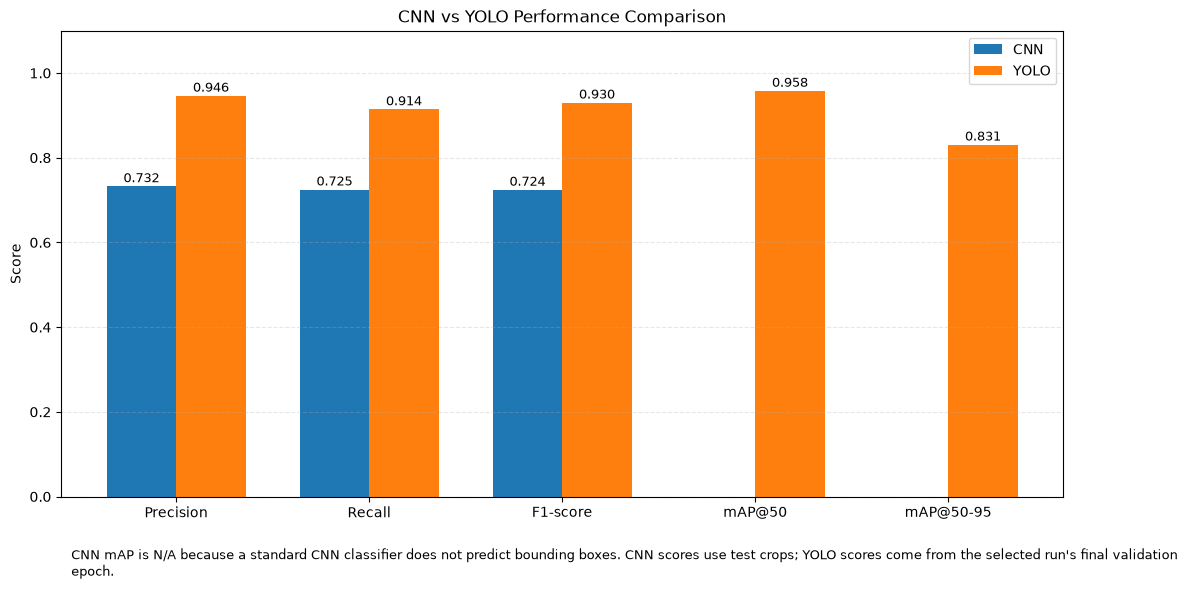


Comparison saved to: G:\Code\smart-waste-detection\results\cnn_vs_yolo_metrics.csv


In [44]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import precision_recall_fscore_support
from torchvision import datasets

# ==========================================================
# 1. PROJECT PATHS
# ==========================================================
PROJECT_DIR = Path(r"G:\Code\smart-waste-detection")
CNN_TEST_DIR = PROJECT_DIR / "cnn_crops" / "test"
YOLO_RUNS_DIR = PROJECT_DIR / "results" / "yolo_runs"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


# ==========================================================
# 2. AUTOMATICALLY FIND CNN CHECKPOINT
# ==========================================================
# Searches for .pt and .pth files, excluding typical YOLO run folders.

checkpoint_files = [
    p for p in PROJECT_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".pt", ".pth"}
    and "yolo_runs" not in str(p).lower()
    and "runs/detect" not in str(p).lower()
    and "runs\\detect" not in str(p).lower()
]

# Prefer checkpoints in the models directory and filenames
# that indicate a best CNN checkpoint.
def checkpoint_rank(path):
    name = path.name.lower()
    in_models = "models" in [part.lower() for part in path.parts]
    return (
        "cnn" in name,
        "best" in name,
        in_models,
        path.stat().st_mtime
    )

if not checkpoint_files:
    raise FileNotFoundError(
        f"No .pt or .pth checkpoints found in {PROJECT_DIR}.\n"
        "Run your CNN training cell and check where it saves the model."
    )

checkpoint_files.sort(key=checkpoint_rank, reverse=True)

print("\nCNN checkpoint candidates:")
for i, path in enumerate(checkpoint_files, start=1):
    print(f"{i}. {path}")

# Automatically select the highest-ranked candidate.
# Verify the printed path is a CNN checkpoint, not a YOLO model.
CNN_MODEL_PATH = checkpoint_files[0]

print("\nSelected checkpoint:", CNN_MODEL_PATH)

if "WasteCNN" not in globals():
    raise NameError(
        "WasteCNN is not defined. Run the cell containing your CNN model class first."
    )

if not CNN_TEST_DIR.exists():
    raise FileNotFoundError(
        f"CNN test crops not found: {CNN_TEST_DIR}"
    )

if "test_transform" not in globals():
    raise NameError(
        "test_transform is not defined. Run your CNN preprocessing cell first."
    )


# ==========================================================
# 3. LOAD CNN AND CALCULATE TEST METRICS
# ==========================================================
test_dataset = datasets.ImageFolder(
    str(CNN_TEST_DIR),
    transform=test_transform
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Instantiate the same architecture used during training.
cnn_model = WasteCNN(
    num_classes=len(test_dataset.classes)
).to(device)

checkpoint = torch.load(
    CNN_MODEL_PATH,
    map_location=device,
    weights_only=False
)

# Support either a raw state_dict or a checkpoint dictionary.
if isinstance(checkpoint, dict):
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint
else:
    raise ValueError("Unrecognized checkpoint format.")

cnn_model.load_state_dict(state_dict)
cnn_model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = cnn_model(images.to(device))
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

cnn_precision, cnn_recall, cnn_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

print("\nCNN test results:")
print(f"Precision: {cnn_precision:.4f}")
print(f"Recall:    {cnn_recall:.4f}")
print(f"F1-score:  {cnn_f1:.4f}")


# ==========================================================
# 4. AUTOMATICALLY READ YOLO RESULTS
# ==========================================================
if not YOLO_RUNS_DIR.exists():
    raise FileNotFoundError(
        f"YOLO results folder not found: {YOLO_RUNS_DIR}"
    )

csv_files = list(YOLO_RUNS_DIR.rglob("results.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No results.csv files found in {YOLO_RUNS_DIR}"
    )

def find_column(df, candidates):
    normalized = {str(c).strip().lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in normalized:
            return normalized[candidate.lower()]
    return None

def get_best_map95(csv_path):
    df = pd.read_csv(csv_path)
    col = find_column(df, [
        "metrics/mAP50-95(B)",
        "metrics/mAP50-95"
    ])
    if col is None:
        return -1
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    return float(values.max()) if len(values) else -1

# Select the run with the highest recorded validation mAP50-95.
best_csv = max(csv_files, key=get_best_map95)
yolo_df = pd.read_csv(best_csv)

def get_last_metric(df, candidates):
    col = find_column(df, candidates)
    if col is None:
        print("Metric column not found:", candidates)
        return np.nan

    values = pd.to_numeric(df[col], errors="coerce").dropna()
    return float(values.iloc[-1]) if len(values) else np.nan

yolo_precision = get_last_metric(
    yolo_df, ["metrics/precision(B)", "metrics/precision"]
)
yolo_recall = get_last_metric(
    yolo_df, ["metrics/recall(B)", "metrics/recall"]
)
yolo_map50 = get_last_metric(
    yolo_df, ["metrics/mAP50(B)", "metrics/mAP50"]
)
yolo_map95 = get_last_metric(
    yolo_df, ["metrics/mAP50-95(B)", "metrics/mAP50-95"]
)

yolo_f1 = (
    2 * yolo_precision * yolo_recall / (yolo_precision + yolo_recall)
    if np.isfinite(yolo_precision)
    and np.isfinite(yolo_recall)
    and (yolo_precision + yolo_recall) > 0
    else np.nan
)

print("\nYOLO results read from:", best_csv)


# ==========================================================
# 5. COMPARISON TABLE AND SIDE-BY-SIDE GRAPH
# ==========================================================
metrics = [
    "Precision",
    "Recall",
    "F1-score",
    "mAP@50",
    "mAP@50-95"
]

cnn_values = [
    cnn_precision, cnn_recall, cnn_f1, np.nan, np.nan
]

yolo_values = [
    yolo_precision, yolo_recall, yolo_f1,
    yolo_map50, yolo_map95
]

comparison = pd.DataFrame({
    "Metric": metrics,
    "CNN": cnn_values,
    "YOLO": yolo_values
})

display(comparison.round(4))

x = np.arange(len(metrics))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(x - width / 2, cnn_values, width, label="CNN")
bars2 = ax.bar(x + width / 2, yolo_values, width, label="YOLO")

ax.set_title("CNN vs YOLO Performance Comparison")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.10)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()
        if np.isfinite(value):
            ax.annotate(
                f"{value:.3f}",
                (bar.get_x() + bar.get_width() / 2, value),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center",
                fontsize=9
            )

ax.text(
    0.01, -0.17,
    "CNN mAP is N/A because a standard CNN classifier does not "
    "predict bounding boxes. CNN scores use test crops; YOLO scores "
    "come from the selected run's final validation epoch.",
    transform=ax.transAxes,
    fontsize=9,
    wrap=True
)

plt.tight_layout()
plt.show()

output_file = RESULTS_DIR / "cnn_vs_yolo_metrics.csv"
comparison.to_csv(output_file, index=False)

print("\nComparison saved to:", output_file)

YOLO run: G:\Code\smart-waste-detection\results\yolo_runs\baseline


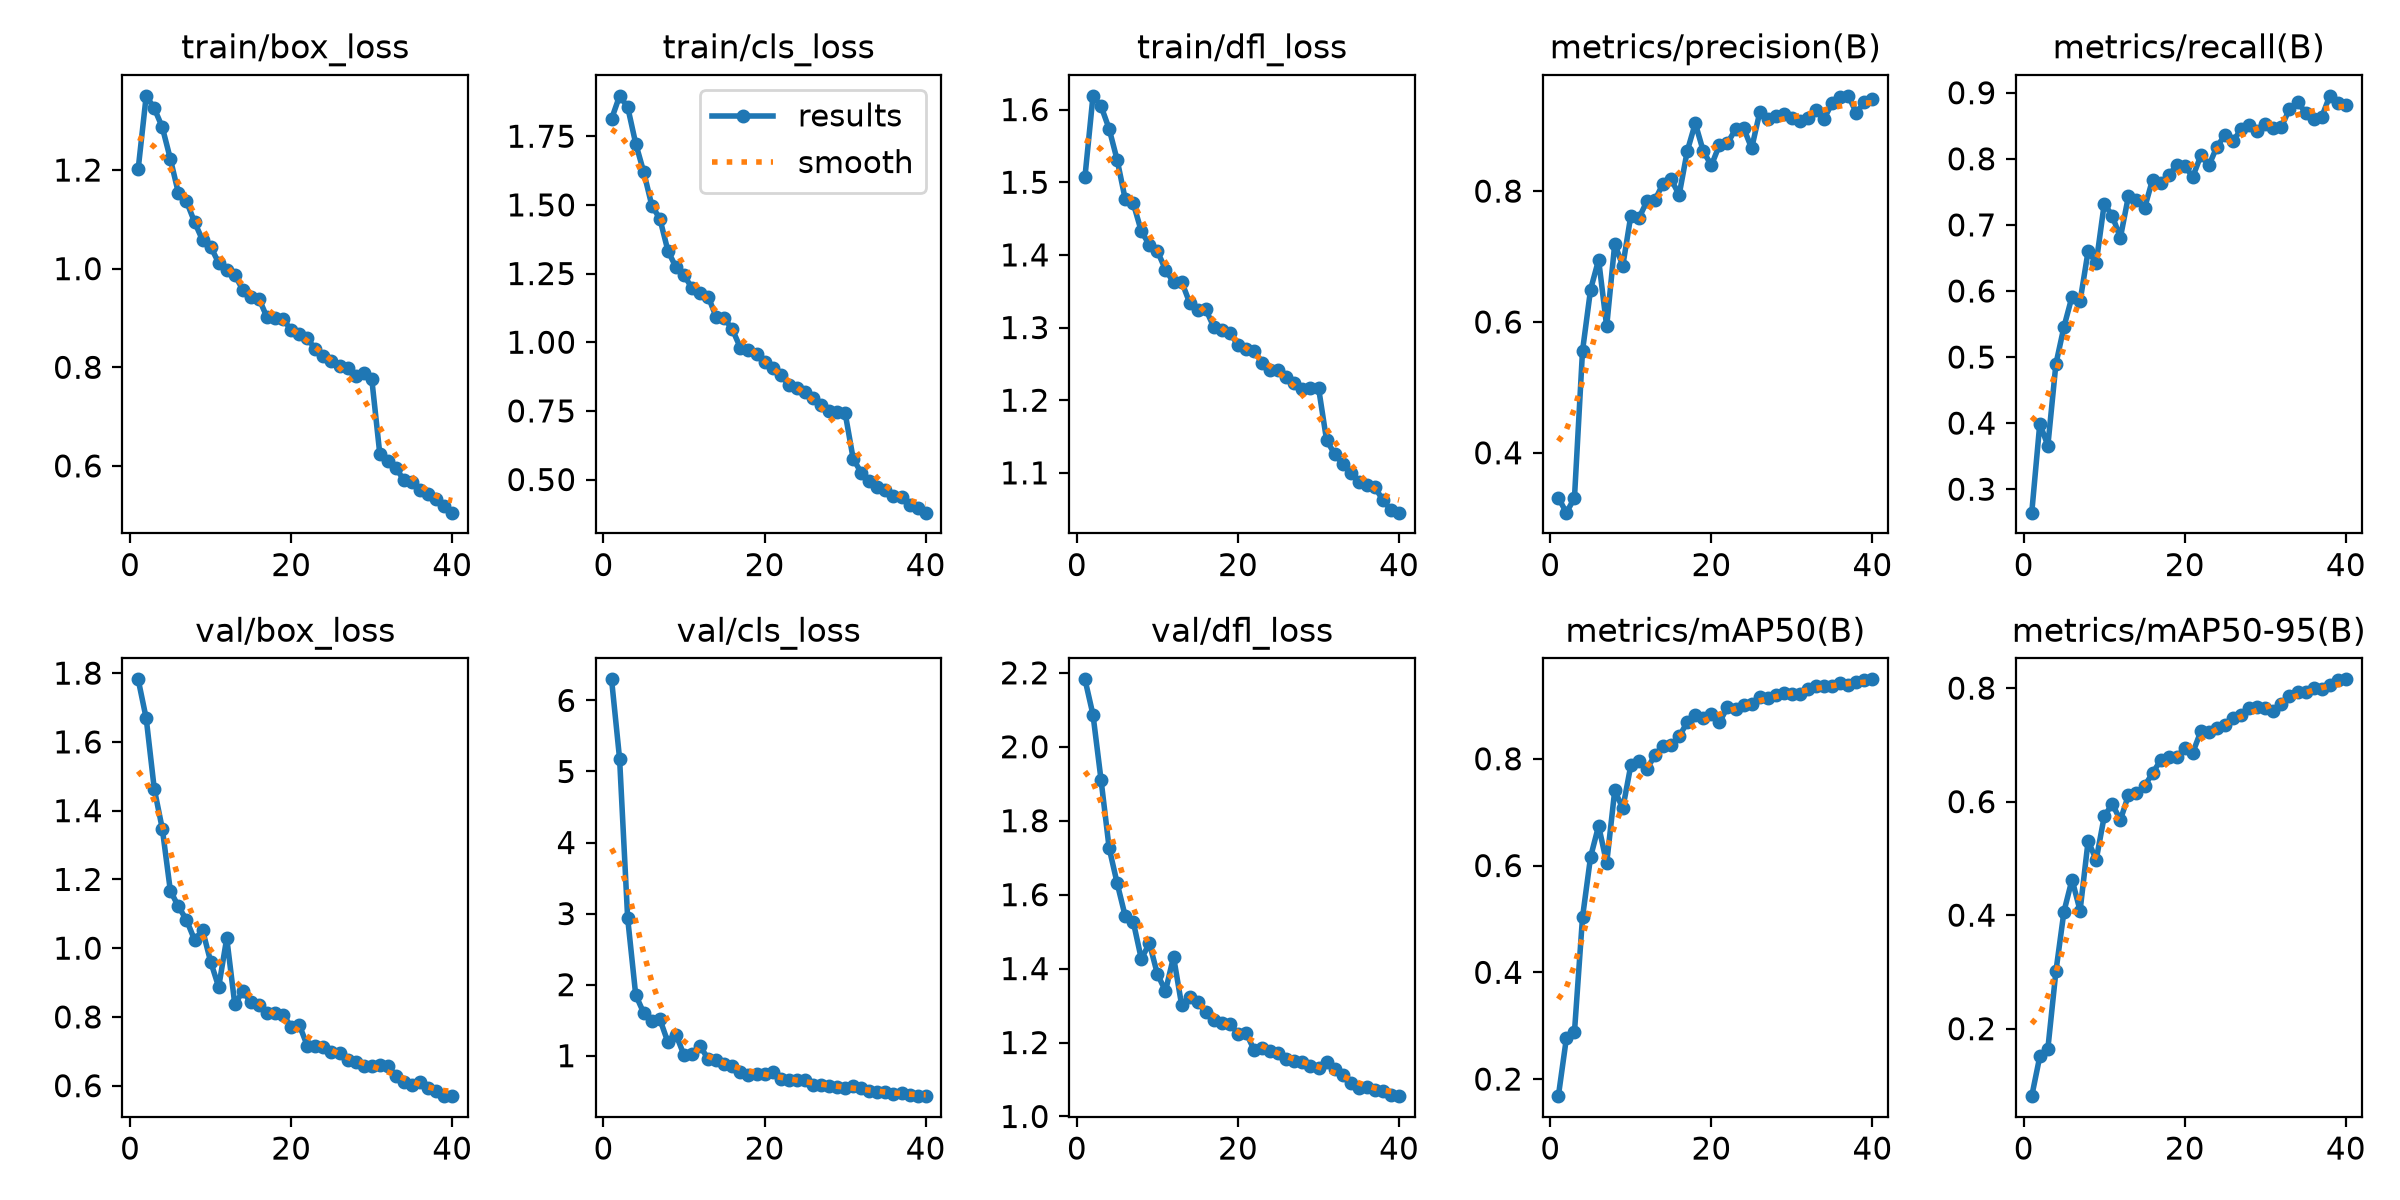

YOLO run: G:\Code\smart-waste-detection\results\yolo_runs\tuning_1


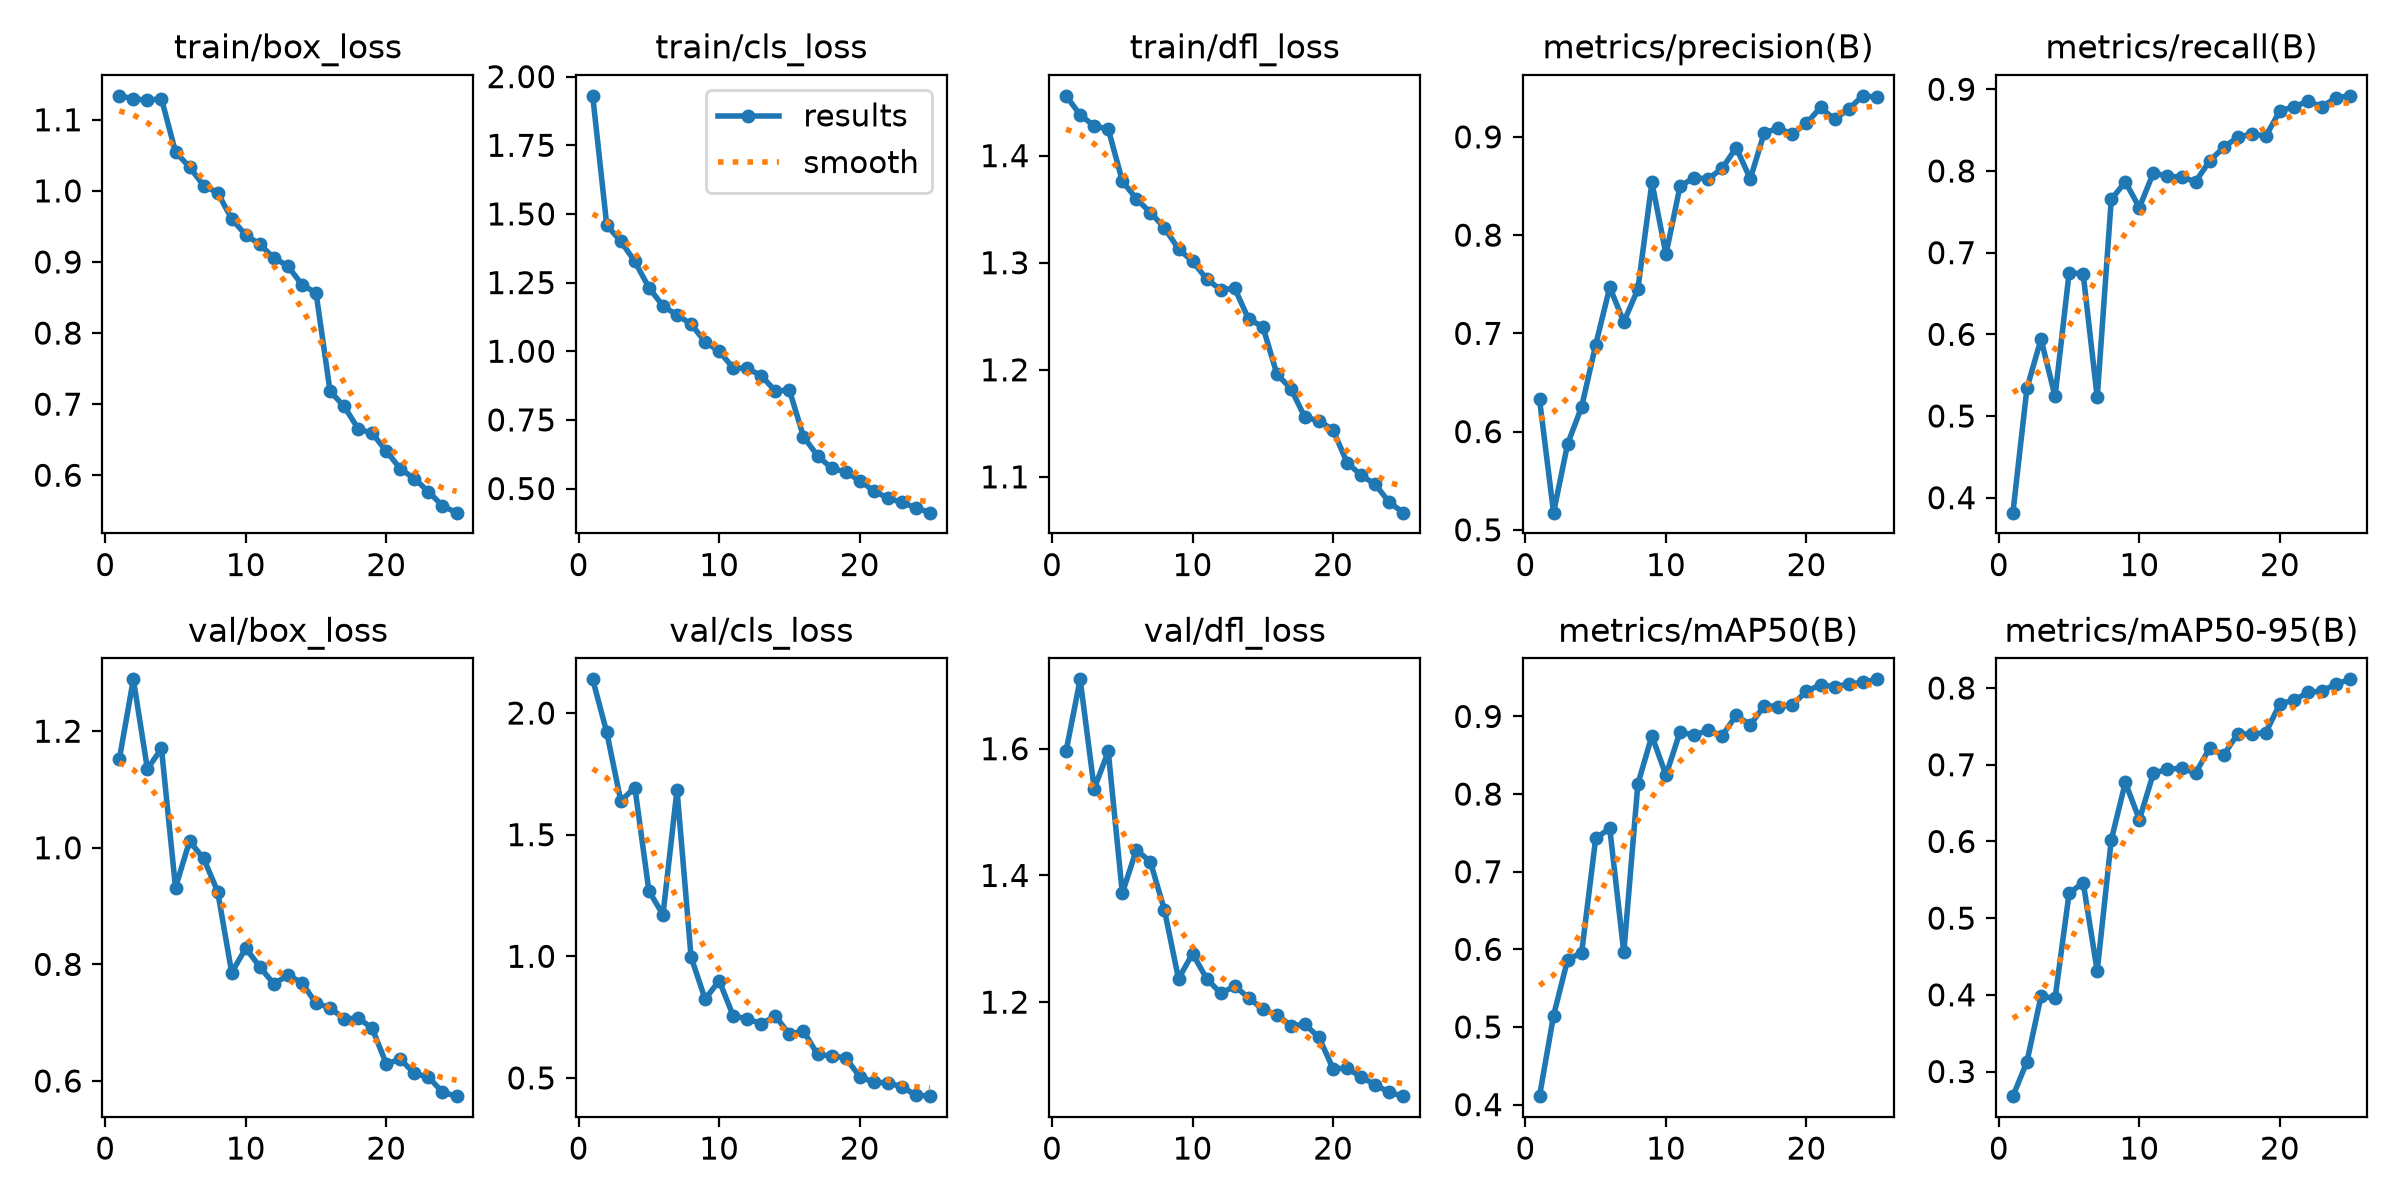

YOLO run: G:\Code\smart-waste-detection\results\yolo_runs\tuning_2


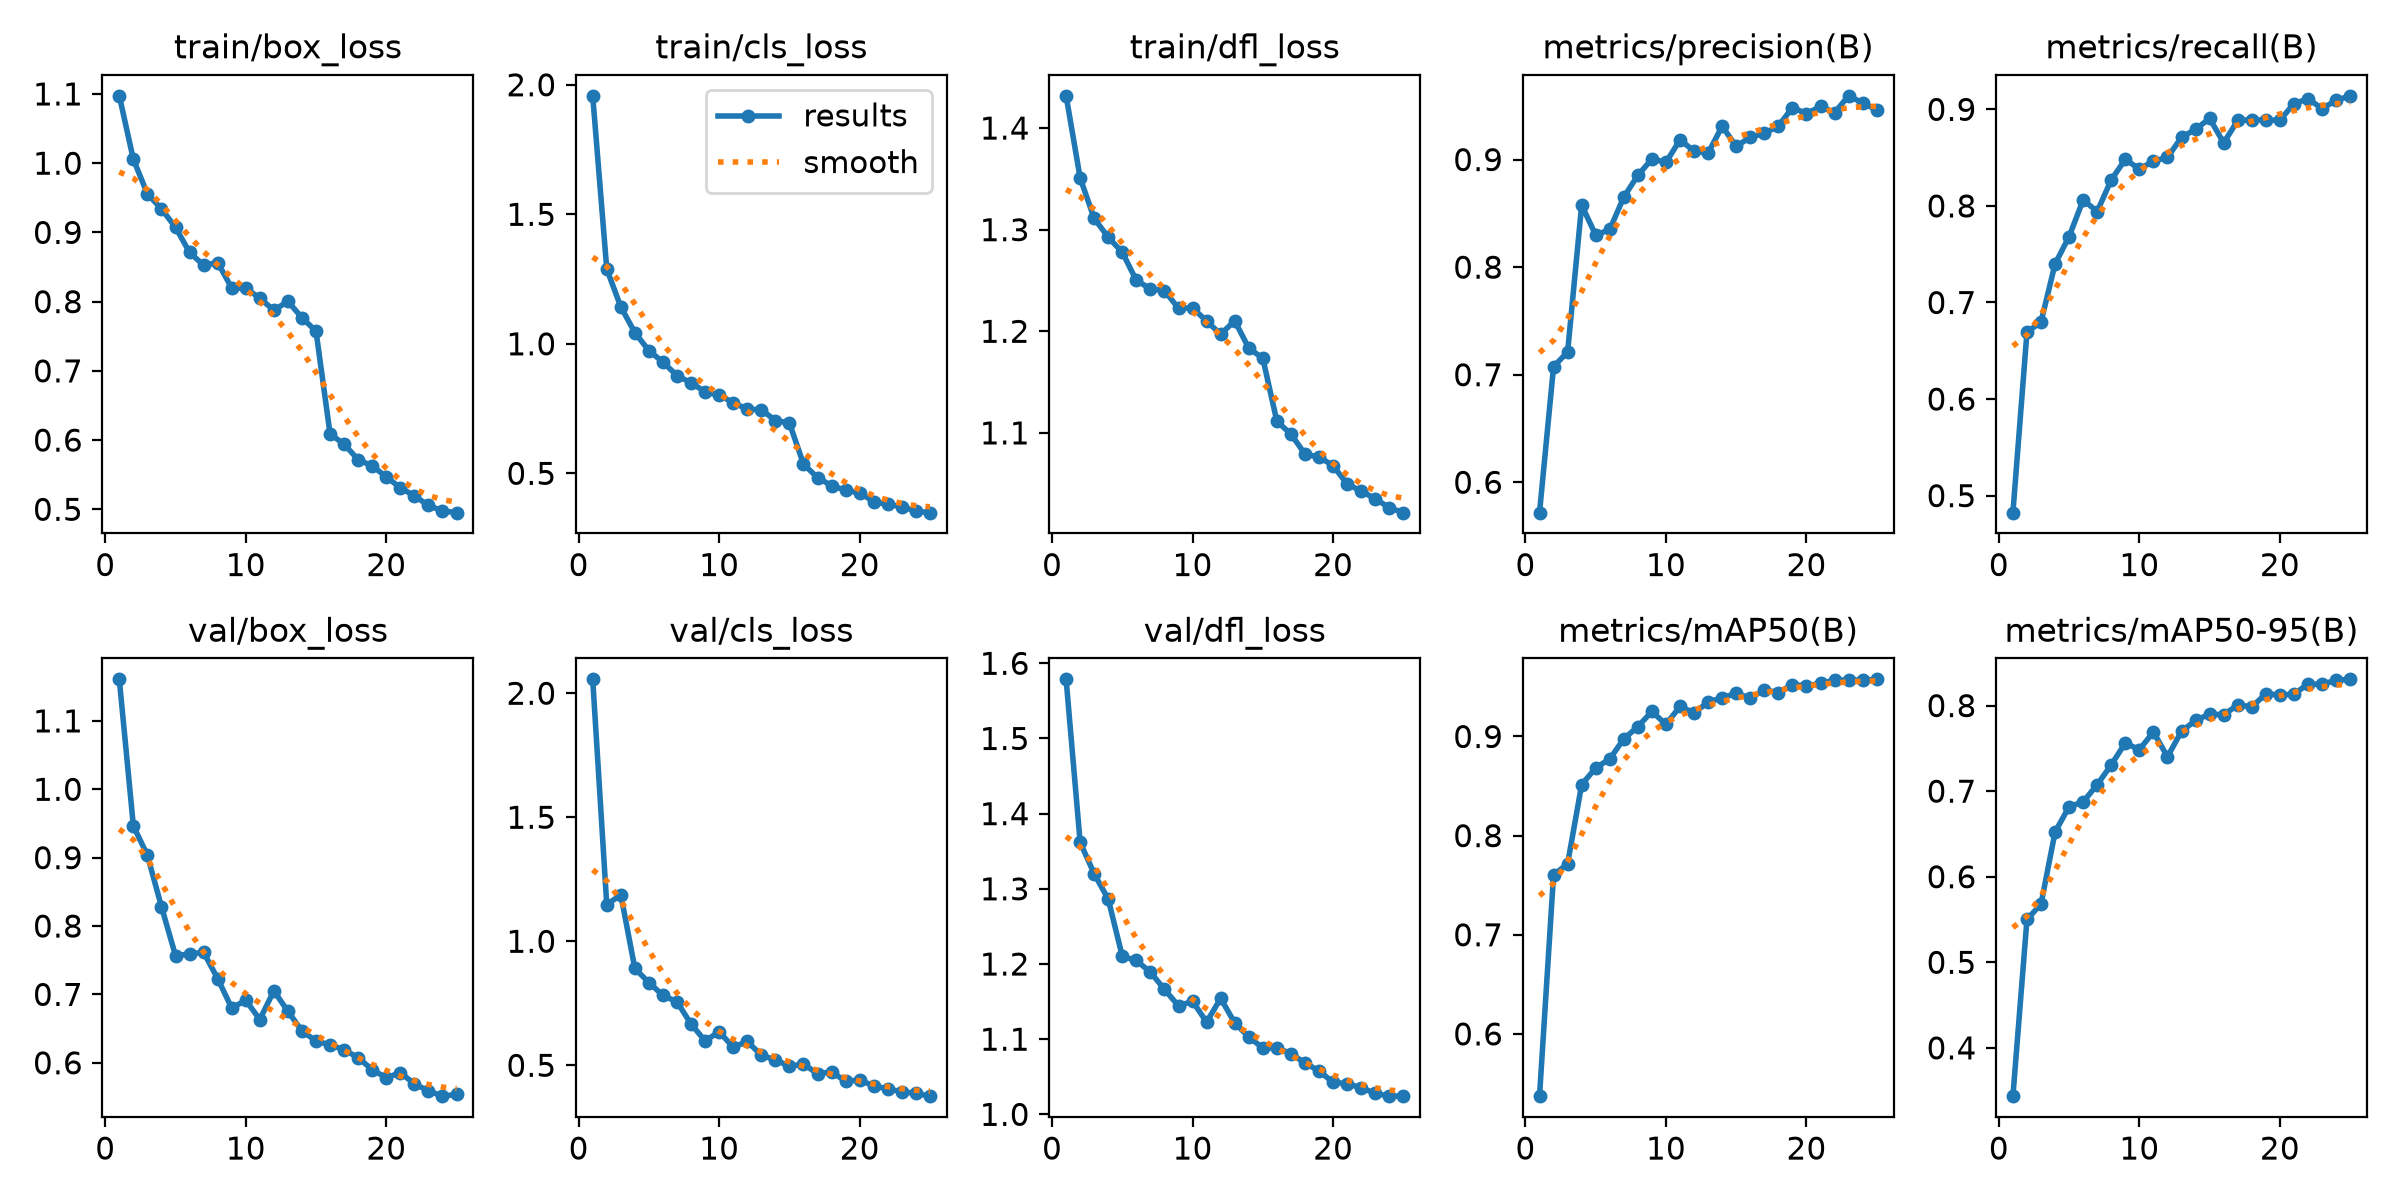

YOLO run: G:\Code\smart-waste-detection\results\yolo_runs\tuning_3


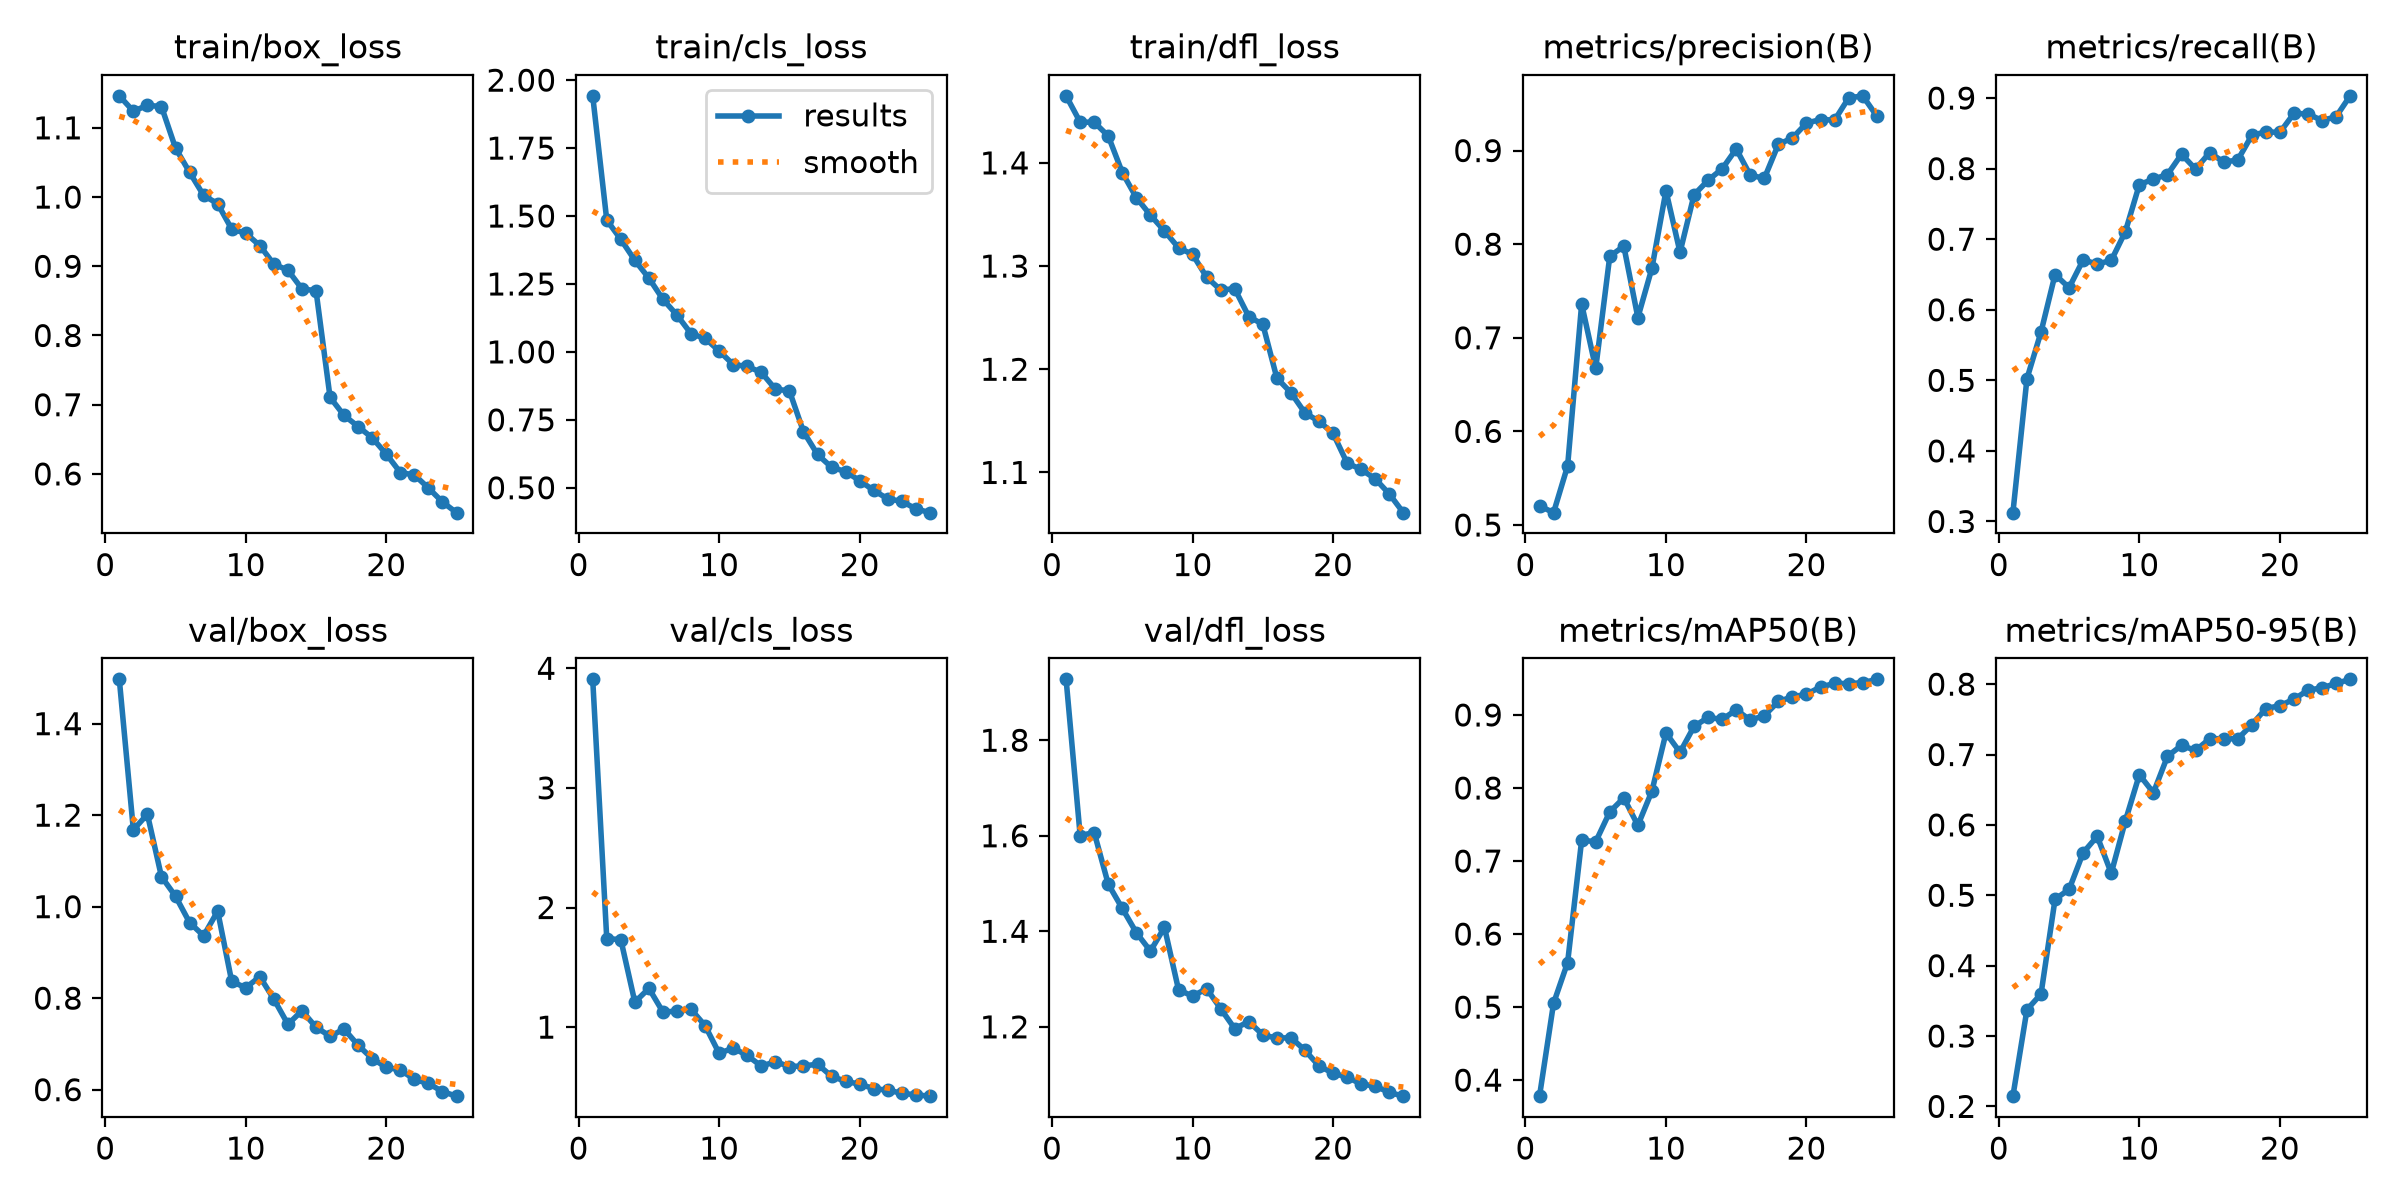

In [45]:
from pathlib import Path
from IPython.display import display, Image

PROJECT_DIR = Path(r"G:\Code\smart-waste-detection")
YOLO_RUNS_DIR = PROJECT_DIR / "results" / "yolo_runs"

graphs = list(YOLO_RUNS_DIR.rglob("results.png"))

if graphs:
    for graph in graphs:
        print(f"YOLO run: {graph.parent}")
        display(Image(filename=str(graph)))
else:
    print("No results.png found. Check your YOLO training run directory.")

CNN Inference Webcam

In [47]:
%pip list | findstr opencv

opencv-python           5.0.0.93
opencv-python-headless  5.0.0.93
Note: you may need to restart the kernel to use updated packages.


In [48]:
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [49]:
%pip install opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   - -------------------------------------- 1.8/44.0 MB 14.4 MB/s eta 0:00:03
   ------ --------------------------------- 7.3/44.0 MB 22.6 MB/s eta 0:00:02
   ---------- ----------------------------- 11.3/44.0 MB 20.7 MB/s eta 0:00:02
   ------------- -------------------------- 14.9/44.0 MB 19.6 MB/s eta 0:00:02
   --------------- ------------------------ 17.6/44.0 MB 18.2 MB/s eta 0:00:02
   ------------------- -------------------- 21.0/44.0 MB 17.7 MB/s eta 0:00:02
   --------------------- ------------------ 24.1/44.0 MB 17.3 MB/s eta 0:00:02
   ------------------------ --------------- 27.3/44.0 MB 16.9 MB/s eta 0:00:01
   -------------------------- ------------- 29.6/44.0 MB 16.3 MB/s eta 0:00:01
   ----------------------------- ---------- 32.0/44.0 MB 15.9 MB/s eta 0:00:01
   ------------------------------- -------- 34.6/44.0 MB 15.4 MB/s eta 0:00:01
   --------------------------------- ------ 37.0/44.0 MB 15.1 M


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import cv2

print("OpenCV version:", cv2.__version__)

cap = cv2.VideoCapture(0)

if cap.isOpened():
    ret, frame = cap.read()

    if ret:
        cv2.imshow("Webcam Test", frame)
        cv2.waitKey(0)
    else:
        print("Camera opened, but no frame was captured.")
else:
    print("Could not open webcam.")

cap.release()
cv2.destroyAllWindows()

OpenCV version: 5.0.0


In [5]:
print("WasteCNN defined:", "WasteCNN" in globals())

WasteCNN defined: False


In [6]:
from pathlib import Path

project = Path(r"G:\Code\smart-waste-detection")

for notebook in project.glob("*.ipynb"):
    print(notebook)

In [8]:
print("WasteCNN defined:", "WasteCNN" in globals())

WasteCNN defined: False


In [10]:
from pathlib import Path
import json

PROJECT_DIR = Path(r"G:\Code\smart-waste-detection")

for notebook_path in PROJECT_DIR.rglob("*.ipynb"):
    try:
        notebook = json.loads(
            notebook_path.read_text(encoding="utf-8")
        )

        for cell_number, cell in enumerate(notebook.get("cells", [])):
            source = "".join(cell.get("source", []))

            if "class WasteCNN" in source:
                print(f"\nFound in: {notebook_path}")
                print(f"Cell number: {cell_number + 1}")
                print("-" * 50)
                print(source)

    except Exception as error:
        print(f"Could not read {notebook_path.name}: {error}")

In [12]:
from pathlib import Path
import torch

PROJECT_DIR = Path(r"G:\Code\smart-waste-detection")
MODEL_PATH = PROJECT_DIR / "models" / "cnn_best.pt"
TEST_DIR = PROJECT_DIR / "cnn_crops" / "test"

print("Checkpoint exists:", MODEL_PATH.exists())
print("Test dataset exists:", TEST_DIR.exists())
print("WasteCNN defined:", "WasteCNN" in globals())
print("IMG_SIZE:", globals().get("IMG_SIZE", "not defined"))
print("GPU available:", torch.cuda.is_available())

Checkpoint exists: True
Test dataset exists: True
WasteCNN defined: False
IMG_SIZE: not defined
GPU available: True


In [13]:
import torch
from pathlib import Path

MODEL_PATH = Path(
    r"G:\Code\smart-waste-detection\models\cnn_best.pt"
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint

    print("\nSaved parameter names and shapes:")
    for name, value in state_dict.items():
        if isinstance(value, torch.Tensor):
            print(f"{name}: {tuple(value.shape)}")
else:
    print("This checkpoint may contain a serialized model object.")

Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['features.0.weight', 'features.0.bias', 'features.1.weight', 'features.1.bias', 'features.1.running_mean', 'features.1.running_var', 'features.1.num_batches_tracked', 'features.4.weight', 'features.4.bias', 'features.5.weight', 'features.5.bias', 'features.5.running_mean', 'features.5.running_var', 'features.5.num_batches_tracked', 'features.8.weight', 'features.8.bias', 'features.9.weight', 'features.9.bias', 'features.9.running_mean', 'features.9.running_var', 'features.9.num_batches_tracked', 'features.12.weight', 'features.12.bias', 'features.13.weight', 'features.13.bias', 'features.13.running_mean', 'features.13.running_var', 'features.13.num_batches_tracked', 'classifier.2.weight', 'classifier.2.bias', 'classifier.5.weight', 'classifier.5.bias']

Saved parameter names and shapes:
features.0.weight: (32, 3, 3, 3)
features.0.bias: (32,)
features.1.weight: (32,)
features.1.bias: (32,)
features.1.running_mean: (32,

In [15]:
import torch
import torch.nn as nn

class WasteCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),  # 0
            nn.BatchNorm2d(32),                          # 1
            nn.ReLU(inplace=True),                       # 2
            nn.MaxPool2d(2),                             # 3

            nn.Conv2d(32, 64, kernel_size=3, padding=1), # 4
            nn.BatchNorm2d(64),                          # 5
            nn.ReLU(inplace=True),                       # 6
            nn.MaxPool2d(2),                             # 7

            nn.Conv2d(64, 128, kernel_size=3, padding=1),# 8
            nn.BatchNorm2d(128),                         # 9
            nn.ReLU(inplace=True),                       # 10
            nn.MaxPool2d(2),                             # 11

            nn.AdaptiveAvgPool2d((4, 4))                 # 12
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),                                # 0
            nn.Dropout(0.3),                             # 1
            nn.Linear(128 * 4 * 4, 128),                 # 2
            nn.ReLU(inplace=True),                       # 3
            nn.Dropout(0.3),                             # 4
            nn.Linear(128, num_classes)                  # 5
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [17]:
from pathlib import Path

MODEL_PATH = Path(
    r"G:\Code\smart-waste-detection\models\cnn_best.pt"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model = WasteCNN(num_classes=6).to(device)

# Strict loading checks that every parameter name and shape matches.
model.load_state_dict(checkpoint, strict=True)

model.eval()

print("CNN checkpoint loaded successfully!")
print("Device:", device)
print("Number of classes:", 6)

RuntimeError: Error(s) in loading state_dict for WasteCNN:
	Unexpected key(s) in state_dict: "features.13.weight", "features.13.bias", "features.13.running_mean", "features.13.running_var", "features.13.num_batches_tracked", "features.12.weight", "features.12.bias". 
	size mismatch for classifier.2.weight: copying a param with shape torch.Size([128, 256]) from checkpoint, the shape in current model is torch.Size([128, 2048]).

In [16]:
import cv2
import torch
import numpy as np
from pathlib import Path
from torchvision import transforms

# 1. Load the trained CNN
PROJECT_DIR = Path(r"G:\Code\smart-waste-detection")
MODEL_PATH = PROJECT_DIR / "models" / "cnn_best.pt"
TEST_DIR = PROJECT_DIR / "cnn_crops" / "test"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Use the class names from the training dataset
from torchvision.datasets import ImageFolder

class_names = ImageFolder(TEST_DIR).classes

img_size = globals().get("IMG_SIZE", 128)

model = WasteCNN(num_classes=len(class_names)).to(device)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

if "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]
elif "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]

model.load_state_dict(checkpoint)
model.eval()

# IMPORTANT: Match the normalization used during CNN training
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 2. Start webcam (0 = default webcam)
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Could not open webcam. Try changing camera index to 1.")

print("Press Q to quit webcam inference.")

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            print("Could not read webcam frame.")
            break

        # Convert BGR to RGB for model input
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image_tensor = transform(rgb).unsqueeze(0).to(device)

        # 3. Predict
        with torch.no_grad():
            outputs = model(image_tensor)
            probabilities = torch.softmax(outputs, dim=1)[0]
            confidence, predicted_idx = probabilities.max(dim=0)

        label = class_names[predicted_idx.item()]
        conf = confidence.item() * 100

        # Display prediction
        text = f"{label}: {conf:.1f}%"
        cv2.putText(
            frame, text, (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX, 1,
            (0, 255, 0), 2, cv2.LINE_AA
        )

        cv2.imshow("CNN Waste Classification", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

RuntimeError: Error(s) in loading state_dict for WasteCNN:
	Unexpected key(s) in state_dict: "features.13.weight", "features.13.bias", "features.13.running_mean", "features.13.running_var", "features.13.num_batches_tracked", "features.12.weight", "features.12.bias". 
	size mismatch for classifier.2.weight: copying a param with shape torch.Size([128, 256]) from checkpoint, the shape in current model is torch.Size([128, 2048]).